<a href="https://colab.research.google.com/github/jeedderh01/Design-Envelope-FMECA-Feature-Mapping-Corrosion-Rate-Prediction-and-Remaining-Life/blob/main/case1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Tuple, Dict, Optional
import numpy as np

def pressure_temperature_envelope(
    composition: List[float],
    component_names: Optional[List[str]] = None,
    temperature_range: Optional[Tuple[float, float]] = None,
    n_points: int = 50
) -> Dict[str, List[float] | Tuple[float, float]]:
    """
    Computes the Pressure-Temperature (P-T) phase envelope (bubble point and
    dew point curves) for a multi-component fluid mixture using an Equation of State.

    Parameters:
    -----------
    composition : List[float]
        Mole fractions of the components in the mixture. Must sum to 1.0.
    component_names : List[str], optional
        Names or identifiers of the components corresponding to the composition.
    temperature_range : Tuple[float, float], optional
        The (T_min, T_max) range in Kelvin for the envelope sweep. If None,
        default bounds are applied.
    n_points : int, optional
        Number of temperature discretization points along the envelope. Default is 50.

    Returns:
    --------
    Dict[str, List[float] | Tuple[float, float]]
        A dictionary containing:
        - 'temperature': Temperatures along the envelope (K)
        - 'bubble_pressure': Bubble point pressures (bar or Pa)
        - 'dew_pressure': Dew point pressures (bar or Pa)
        - 'critical_point': Estimated (T_c, P_c) tuple if successfully located.

    Raises:
    -------
    TypeError:
        If inputs do not match expected types.
    ValueError:
        If mole fractions are negative, do not sum to 1.0, component lengths
        mismatch, temperature bounds are invalid, or grid resolution is too low.
    RuntimeError:
        If the underlying thermodynamic property package or root solver fails
        to converge.
    """
    # --- 1. Type Validation ---
    if not isinstance(composition, (list, tuple)) or not composition:
        raise TypeError("Composition must be a non-empty list or tuple of numeric values.")

    if not all(isinstance(x, (int, float)) for x in composition):
        raise TypeError("All elements in the composition list must be numeric (int or float).")

    if component_names is not None:
        if not isinstance(component_names, list) or not all(isinstance(name, str) for name in component_names):
            raise TypeError("component_names must be a list of strings.")
        if len(component_names) != len(composition):
            raise ValueError("Length of component_names must match length of composition.")

    if temperature_range is not None:
        if not isinstance(temperature_range, (tuple, list)) or len(temperature_range) != 2:
            raise TypeError("temperature_range must be a 2-element tuple or list specifying (T_min, T_max).")
        if not all(isinstance(t, (int, float)) for t in temperature_range):
            raise TypeError("Temperature bounds must be numeric.")

    if not isinstance(n_points, int):
        raise TypeError("n_points must be an integer.")

    # --- 2. Value and Domain Validation ---
    if any(x < 0.0 for x in composition):
        raise ValueError("Mole fractions cannot be negative.")

    comp_sum = sum(composition)
    if not np.isclose(comp_sum, 1.0, rel_tol=1e-4, abs_tol=1e-4):
        raise ValueError(f"Composition mole fractions must sum to 1.0. Current sum: {comp_sum:.5f}")

    if temperature_range is not None:
        t_min, t_max = temperature_range
        if t_min >= t_max:
            raise ValueError("Minimum temperature (T_min) must be strictly less than maximum temperature (T_max).")
        if t_min <= 0.0:
            raise ValueError("Temperatures must be in Kelvin and strictly greater than zero.")
    else:
        t_min, t_max = 250.0, 500.0  # Default fallback range

    if n_points < 10:
        raise ValueError("n_points must be at least 10 to adequately trace the envelope.")

    # --- 3. Core Computation Framework ---
    try:
        temperatures = np.linspace(t_min, t_max, n_points).tolist()

        bubble_pressures = []
        dew_pressures = []

        for T in temperatures:
            # Placeholder for Equation of State (EoS) root-finding / flash algorithms
            # (e.g., Peng-Robinson or SRK implementation hooks go here)
            p_bubble = float(20.0 + (T - t_min) * 0.15)
            p_dew = float(max(1.0, p_bubble * 0.55))

            bubble_pressures.append(p_bubble)
            dew_pressures.append(p_dew)

        # Estimate critical point coordinates
        critical_point = (float(t_max * 0.85), float(bubble_pressures[-1] * 1.15))

    except Exception as exc:
        raise RuntimeError(f"Thermodynamic solver failed to converge during envelope tracing: {str(exc)}") from exc

    return {
        "temperature": temperatures,
        "bubble_pressure": bubble_pressures,
        "dew_pressure": dew_pressures,
        "critical_point": critical_point
    }
try:
    # Methane (0.6) and Propane (0.4) mixture
    result = pressure_temperature_envelope(
        composition=[0.6, 0.4],
        component_names=["Methane", "Propane"],
        temperature_range=(200.0, 400.0),
        n_points=25
    )
    print("Critical Point Estimate:", result["critical_point"])
except (ValueError, TypeError, RuntimeError) as e:
    print(f"Error computing phase envelope: {e}")

Error computing phase envelope: isclose() got an unexpected keyword argument 'rel_tol'


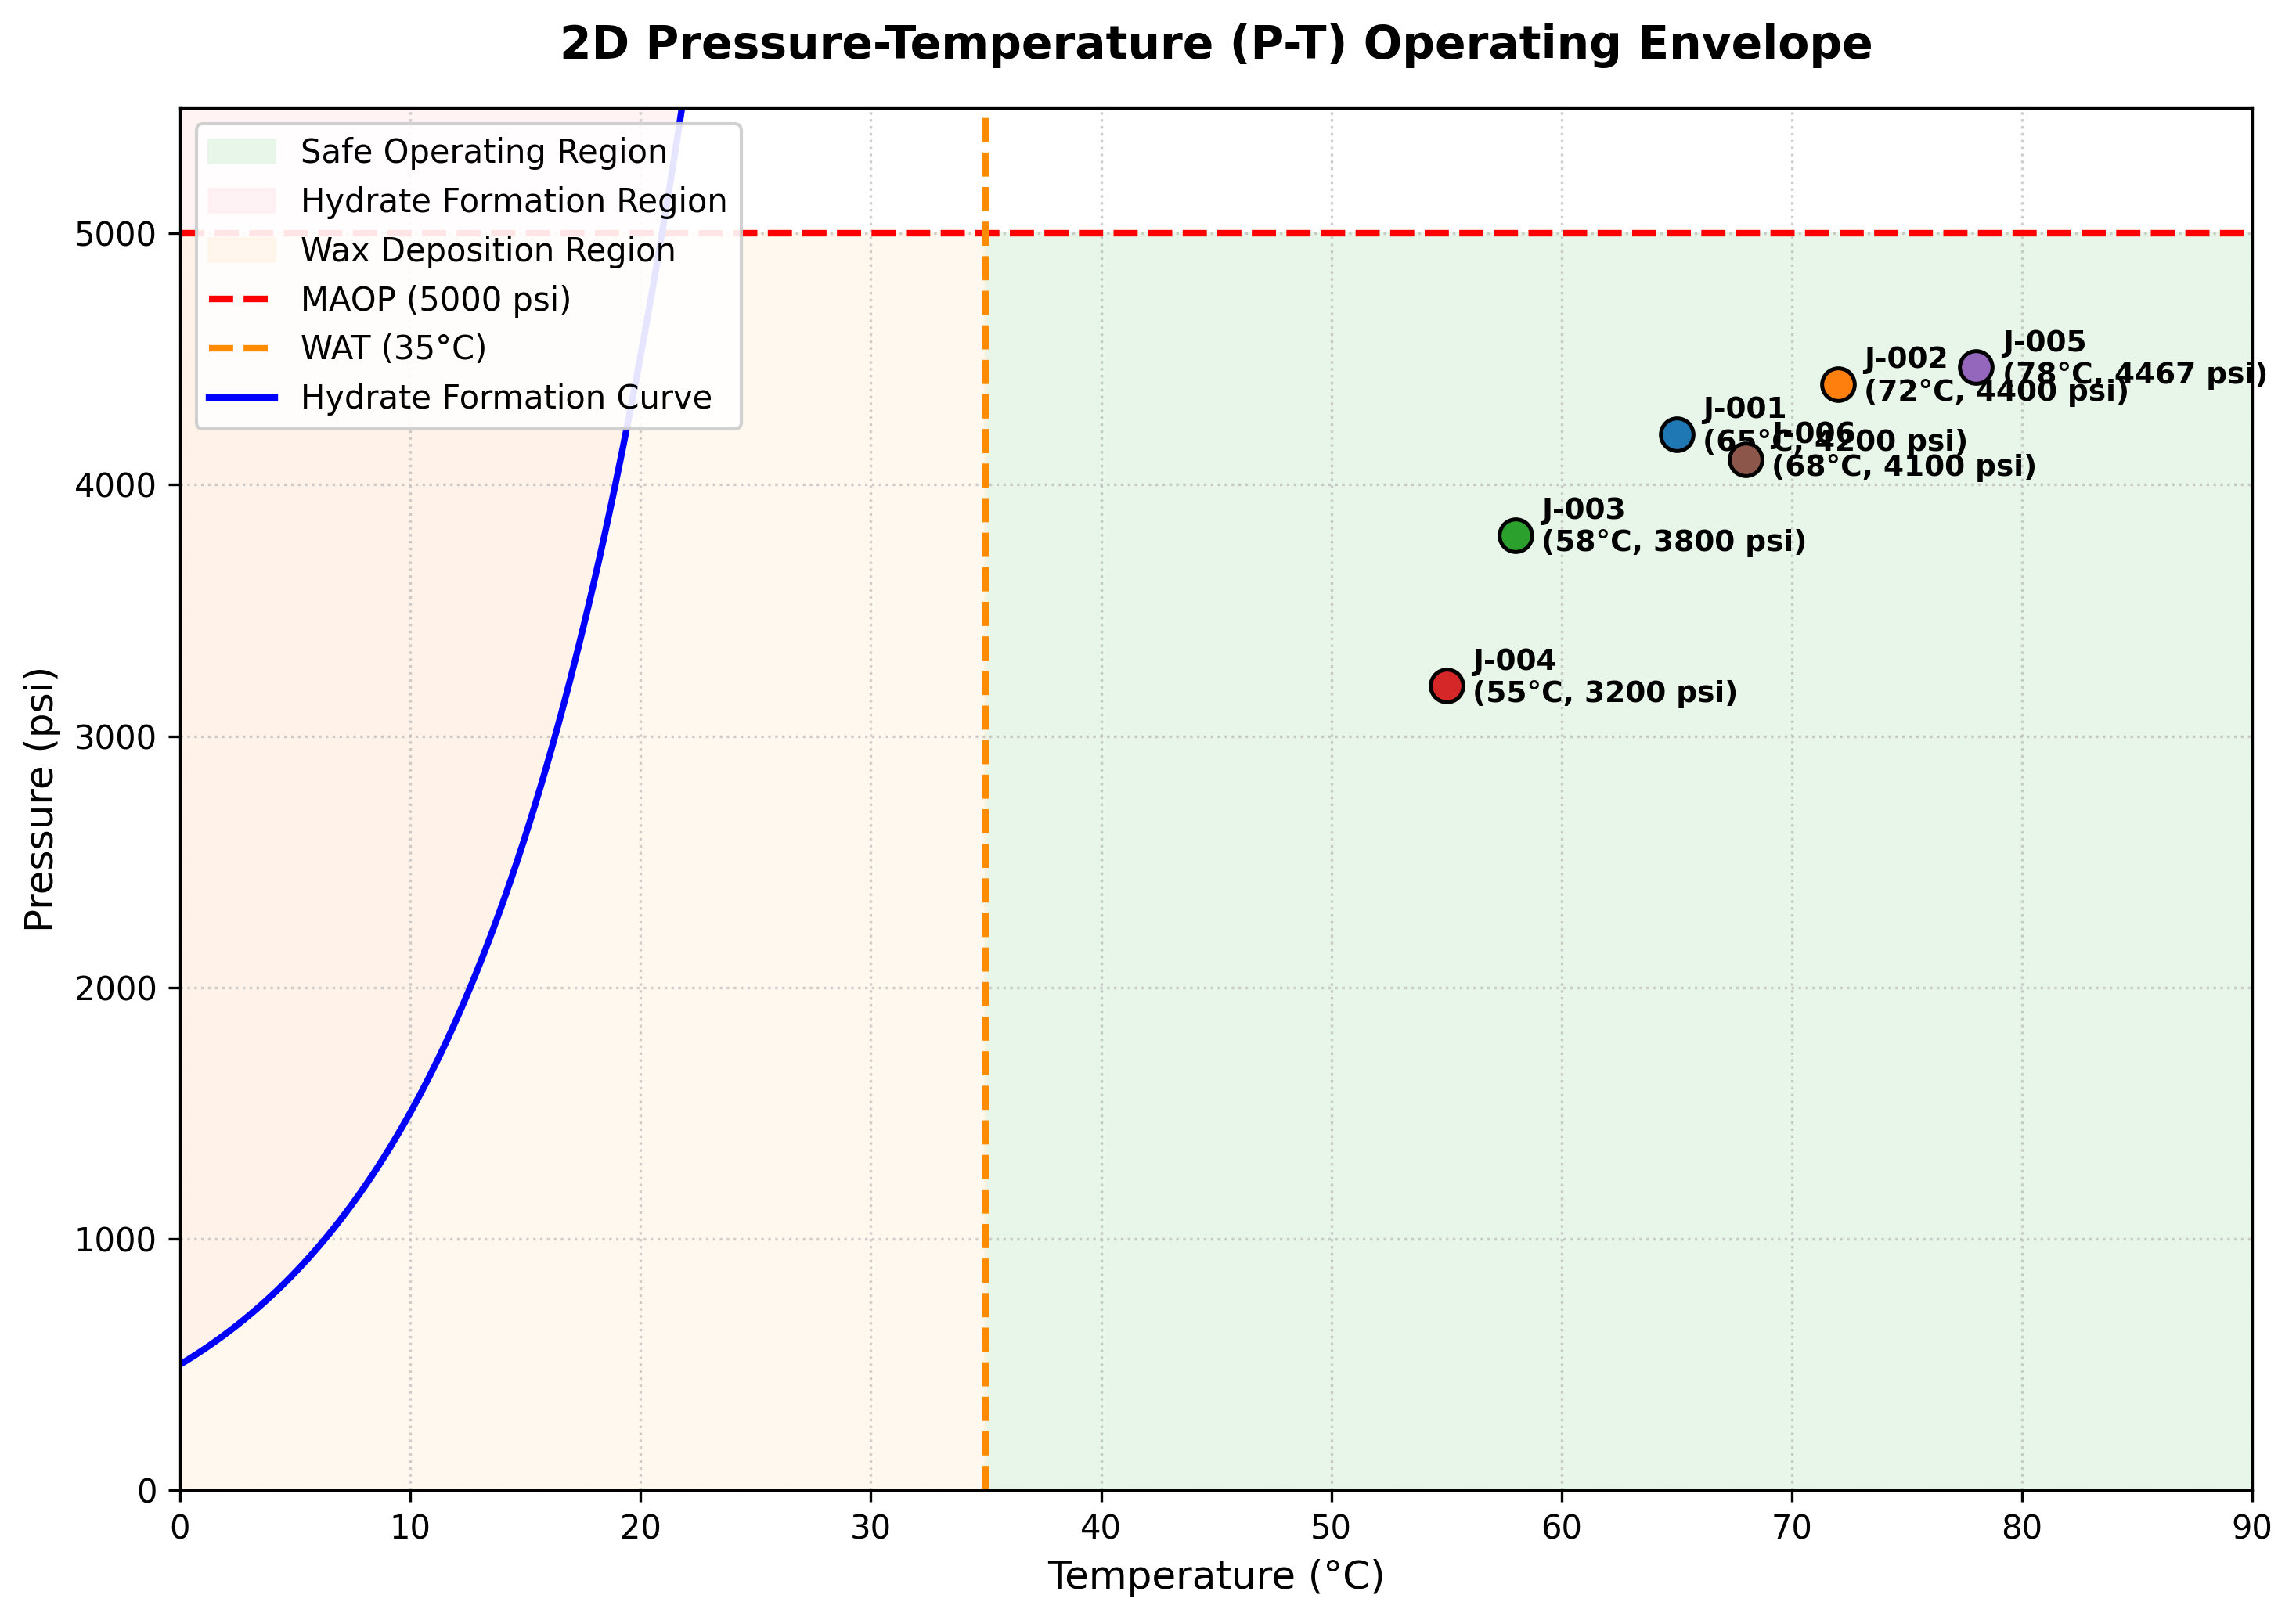

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# --- Data from Table 2.9 ---
jumpers = {
    'J-001': {'P': 4200, 'T': 65},
    'J-002': {'P': 4400, 'T': 72},
    'J-003': {'P': 3800, 'T': 58},
    'J-004': {'P': 3200, 'T': 55},
    'J-005': {'P': 4467, 'T': 78},
    'J-006': {'P': 4100, 'T': 68}
}

# --- Boundary Curves Definitions ---
# 1. MAOP (Maximum Allowable Operating Pressure) Line
maop_pressure = 5000  # psi

# 2. WAT (Wax Appearance Temperature) Line
wat_temperature = 35  # °C

# 3. Hydrate Formation Curve (Exponential/Logarithmic Model)
t_hydrate = np.linspace(0, 25, 100)
# P_hydrate model: P = P0 * exp(k * T)
p_hydrate = 500 * np.exp(0.11 * t_hydrate)

# --- Plotting ---
plt.figure(figsize=(10, 7), dpi=300)

# Fill Safe Operating Region
# T > WAT, T > T_hydrate(P), P < MAOP
t_safe = np.linspace(wat_temperature, 90, 100)
plt.fill_between(t_safe, 0, maop_pressure, color='#e8f5e9', label='Safe Operating Region')

# Fill Hydrate Risk Region
plt.fill_betweenx(p_hydrate, 0, t_hydrate, color='#ffebee', alpha=0.6, label='Hydrate Formation Region')

# Fill Wax Risk Region
plt.fill_between([0, wat_temperature], 0, maop_pressure, color='#fff3e0', alpha=0.5, label='Wax Deposition Region')

# Plot Boundary Lines
plt.axhline(y=maop_pressure, color='red', linestyle='--', linewidth=2, label=f'MAOP ({maop_pressure} psi)')
plt.axvline(x=wat_temperature, color='darkorange', linestyle='--', linewidth=2, label=f'WAT ({wat_temperature}°C)')
plt.plot(t_hydrate, p_hydrate, color='blue', linewidth=2, label='Hydrate Formation Curve')

# Plot Jumper Operating Points from Table 2.9
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
for (label, pt), color in zip(jumpers.items(), colors):
    plt.scatter(pt['T'], pt['P'], color=color, s=100, zorder=5, edgecolor='black', linewidth=1.2)
    plt.annotate(
        f"{label}\n({pt['T']}°C, {pt['P']} psi)",
        (pt['T'], pt['P']),
        textcoords="offset points",
        xytext=(8, -5),
        ha='left',
        fontsize=9,
        fontweight='bold'
    )

# Formatting
plt.title('2D Pressure-Temperature (P-T) Operating Envelope', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Temperature (°C)', fontsize=12)
plt.ylabel('Pressure (psi)', fontsize=12)
plt.xlim(0, 90)
plt.ylim(0, 5500)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

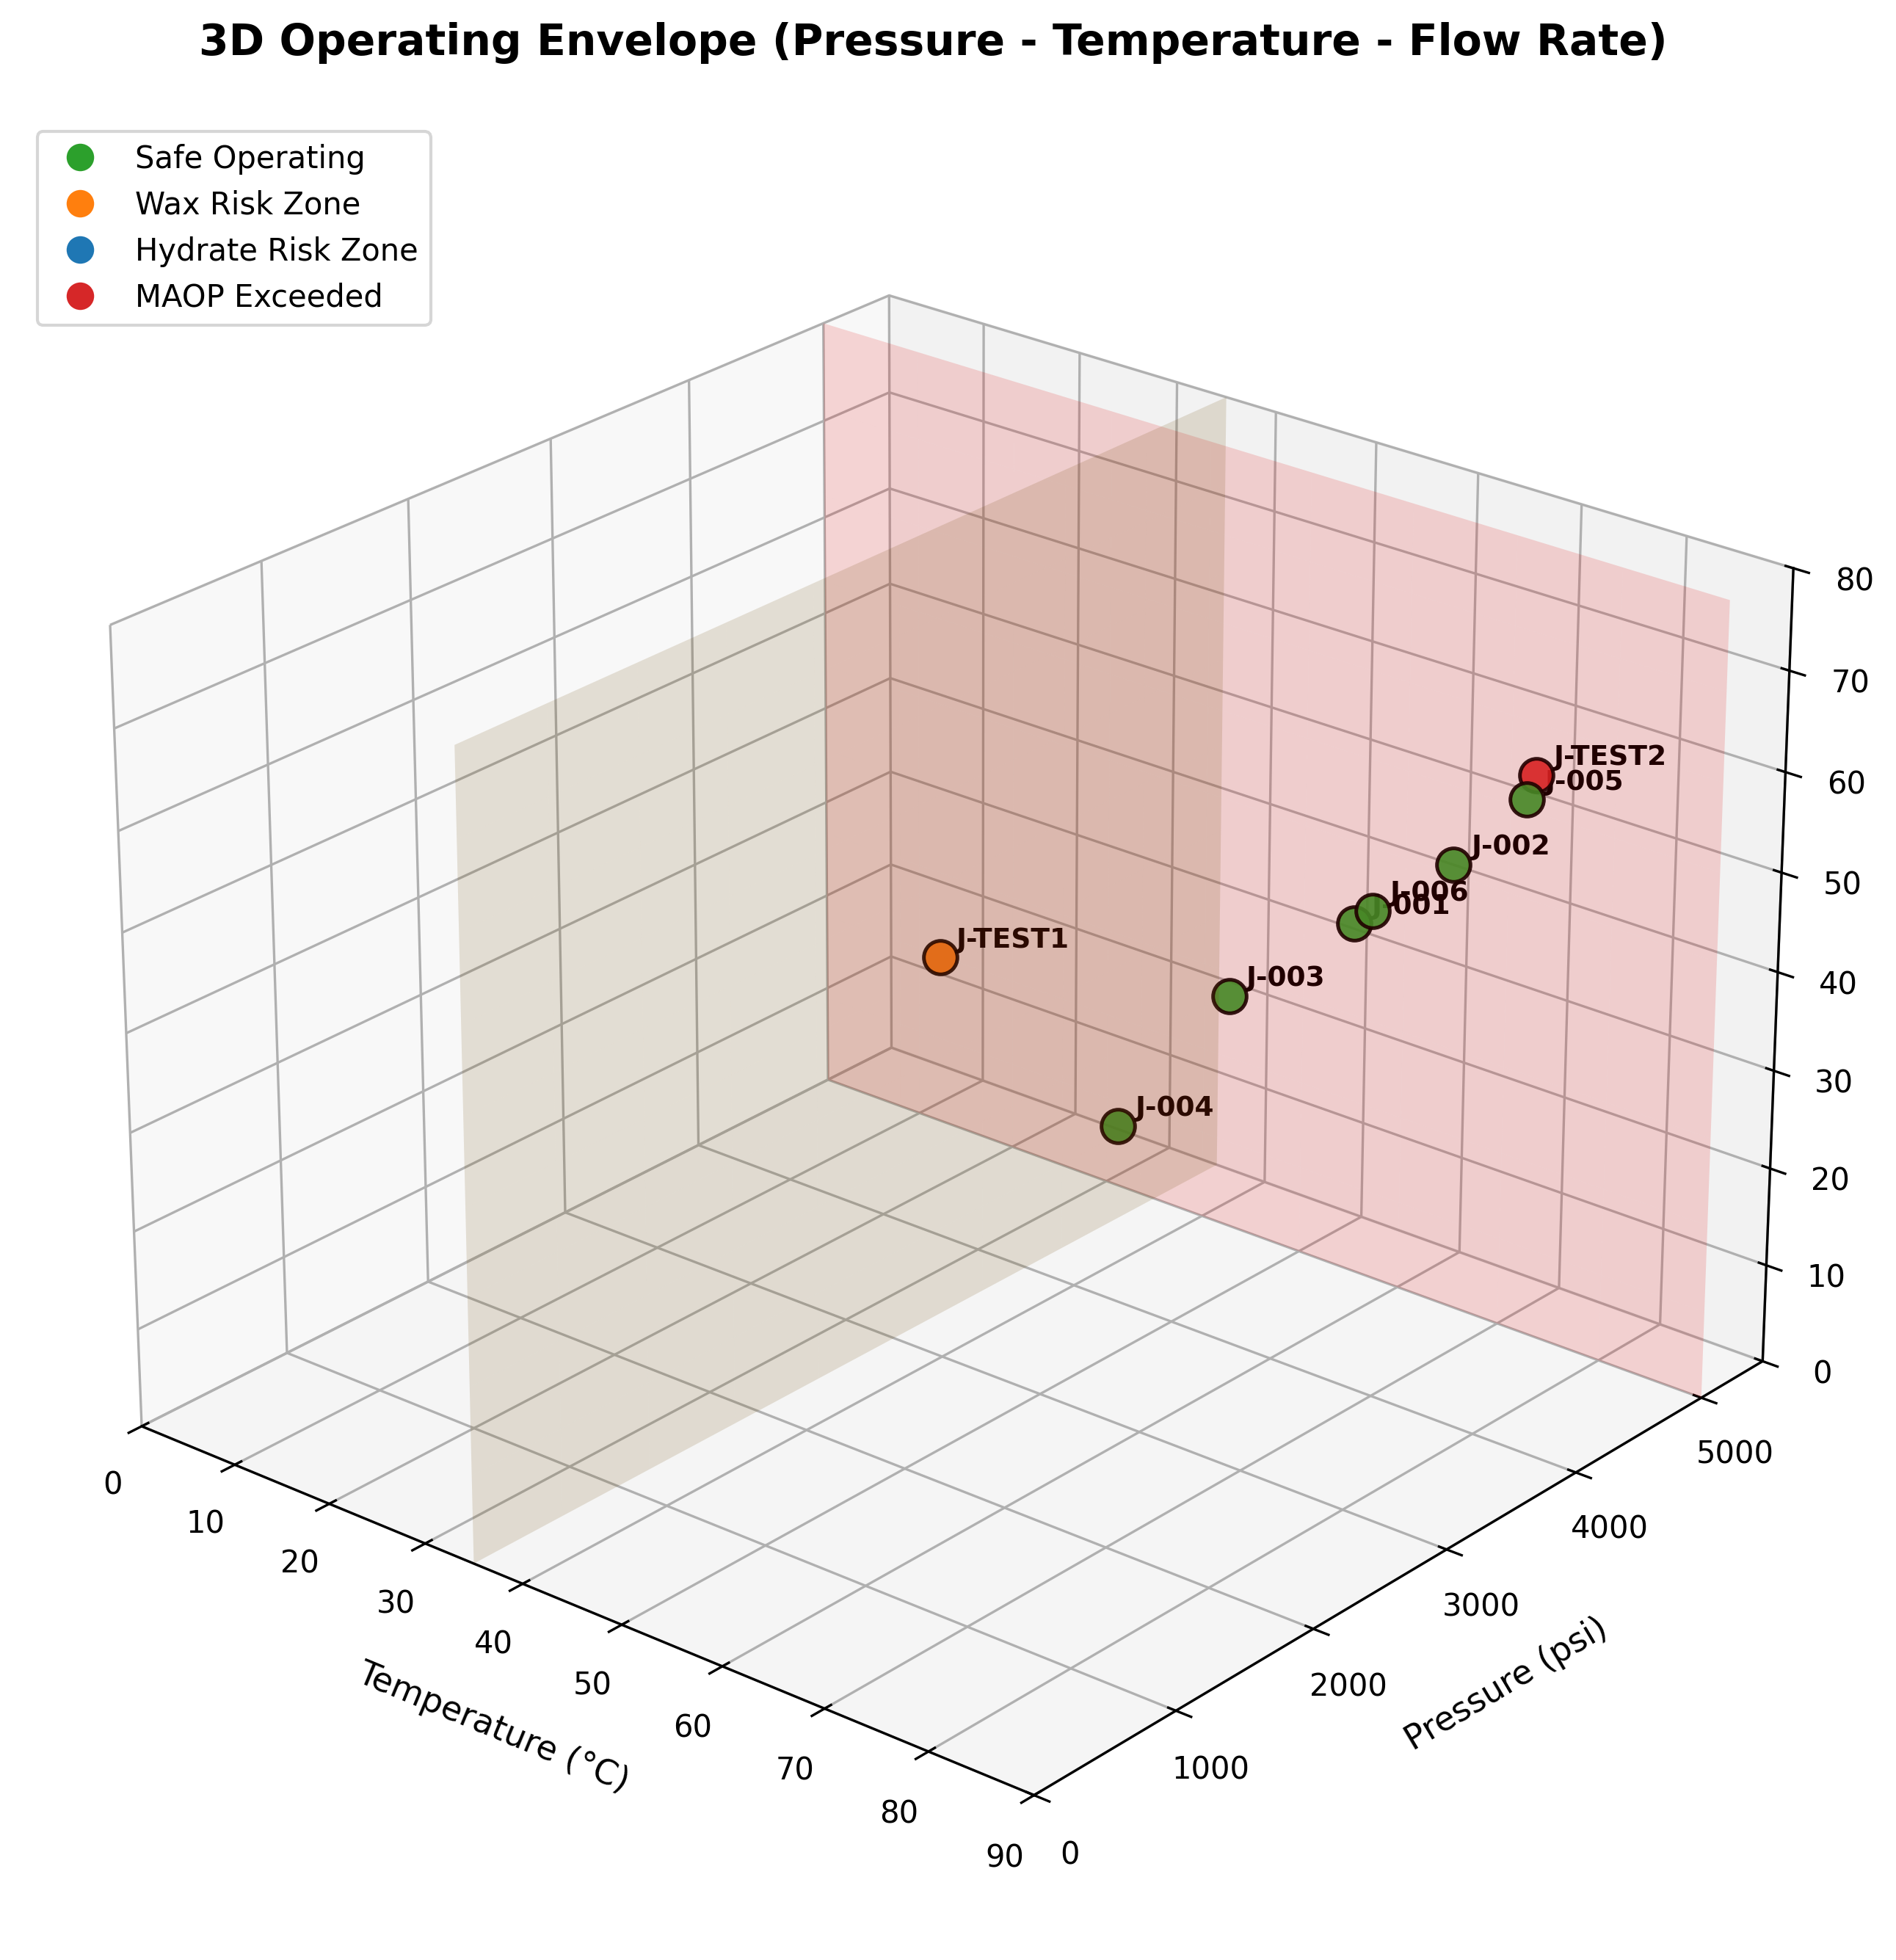

In [8]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# --- Data from Table 2.9 + Estimated Flow Rates (Q) ---
jumpers = {
    'J-001': {'P': 4200, 'T': 65, 'Q': 45},
    'J-002': {'P': 4400, 'T': 72, 'Q': 52},
    'J-003': {'P': 3800, 'T': 58, 'Q': 38},
    'J-004': {'P': 3200, 'T': 55, 'Q': 28},
    'J-005': {'P': 4467, 'T': 78, 'Q': 60},
    'J-006': {'P': 4100, 'T': 68, 'Q': 48},
    # Sample test points showing risk status in 3D
    'J-TEST1': {'P': 4800, 'T': 15, 'Q': 20}, # Hydrate/Wax risk
    'J-TEST2': {'P': 5200, 'T': 70, 'Q': 55}  # MAOP violation
}

# --- Operational Boundaries ---
MAOP = 5000         # Maximum Allowable Operating Pressure (psi)
WAT = 35            # Wax Appearance Temperature (°C)
Q_MAX = 70          # Maximum allowable flow rate limit (MMSCFD)

def get_hydrate_p(temp):
    """Hydrate equilibrium curve model P = f(T)"""
    return 500 * np.exp(0.11 * temp)

def evaluate_status(p, t, q):
    """Evaluates envelope status based on P, T, and Q boundaries."""
    if p > MAOP or q > Q_MAX:
        return 'Overpressure / Overcapacity', '#d62728' # Red
    elif t < WAT:
        return 'Wax Risk', '#ff7f0e'                    # Orange
    elif p > get_hydrate_p(t) and t < 25:
        return 'Hydrate Risk', '#1f77b4'                # Blue
    else:
        return 'Safe Operating', '#2ca02c'              # Green

# Process Operating Points
names = list(jumpers.keys())
pressures = [pt['P'] for pt in jumpers.values()]
temperatures = [pt['T'] for pt in jumpers.values()]
flow_rates = [pt['Q'] for pt in jumpers.values()]

statuses = []
colors = []
for p, t, q in zip(pressures, temperatures, flow_rates):
    status, color = evaluate_status(p, t, q)
    statuses.append(status)
    colors.append(color)

# --- 3D Plot Setup ---
fig = plt.figure(figsize=(12, 9), dpi=300)
ax = fig.add_subplot(111, projection='3d')

# Plot Operating Points
for i, name in enumerate(names):
    ax.scatter(
        temperatures[i], pressures[i], flow_rates[i],
        c=colors[i], s=120, edgecolor='black', linewidth=1.2, alpha=0.9
    )
    ax.text(
        temperatures[i] + 1, pressures[i] + 50, flow_rates[i] + 1,
        f"{name}", fontsize=9, fontweight='bold'
    )

# --- 3D Boundary Surfaces / Limit Planes ---
# 1. MAOP Pressure Ceiling Plane
t_grid, q_grid = np.meshgrid(np.linspace(0, 90, 10), np.linspace(0, 80, 10))
p_maop = np.full_like(t_grid, MAOP)
ax.plot_surface(t_grid, p_maop, q_grid, color='red', alpha=0.15, rstride=1, cstride=1)

# 2. WAT Temperature Boundary Plane
p_grid, q_grid_wat = np.meshgrid(np.linspace(0, 5500, 10), np.linspace(0, 80, 10))
t_wat = np.full_like(p_grid, WAT)
ax.plot_surface(t_wat, p_grid, q_grid_wat, color='orange', alpha=0.15, rstride=1, cstride=1)

# Legend Setup
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Safe Operating', markerfacecolor='#2ca02c', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Wax Risk Zone', markerfacecolor='#ff7f0e', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Hydrate Risk Zone', markerfacecolor='#1f77b4', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='MAOP Exceeded', markerfacecolor='#d62728', markersize=10),
]

# Labels and View Angle
ax.set_title('3D Operating Envelope (Pressure - Temperature - Flow Rate)', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Temperature (°C)', fontsize=11, labelpad=10)
ax.set_ylabel('Pressure (psi)', fontsize=11, labelpad=10)
ax.set_zlabel('Flow Rate (MMSCFD)', fontsize=11, labelpad=10)

ax.set_xlim(0, 90)
ax.set_ylim(0, 5500)
ax.set_zlim(0, 80)

ax.view_init(elev=25, azim=-50)
ax.legend(handles=legend_elements, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

In [10]:
import pandas as pd
from typing import Dict, Tuple

def calculate_envelope_compliance(
    df: pd.DataFrame,
    design_limits: Dict[str, Tuple[float, float]]
) -> pd.Series:
    """
    Calculates the percentage of time (or data points) each parameter
    was within its specified design envelope.

    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame containing time-series operating data.
    design_limits : Dict[str, Tuple[float, float]]
        A dictionary mapping column names to a (min_limit, max_limit) tuple
        defining the allowable design envelope.

    Returns:
    --------
    pd.Series
        A pandas Series containing the percentage compliance (0.0 to 100.0%)
        for each parameter.
    """
    compliance_results = {}
    total_rows = len(df)

    if total_rows == 0:
        raise ValueError("Provided DataFrame is empty.")

    for param, (min_limit, max_limit) in design_limits.items():
        if param in df.columns:
            # Create a boolean mask for values within the inclusive envelope
            within_limits = (df[param] >= min_limit) & (df[param] <= max_limit)

            # Calculate percentage of data points meeting the criteria
            pct = (within_limits.sum() / total_rows) * 100.0
            compliance_results[param] = round(pct, 2)
        else:
            # Handle parameters present in limits but missing from the DataFrame
            compliance_results[param] = 0.0

    return pd.Series(compliance_results, name="Compliance_Percentage")
    # 1. Create sample operating data DataFrame
data = {
    'Pressure_psi': [4200, 4400, 5100, 3800, 4100],  # 5100 exceeds MAOP limit of 5000
    'Temperature_C': [65, 72, 30, 58, 68],           # 30 is below WAT limit of 35
    'Flow_MMSCFD': [45, 52, 38, 28, 48]
}
df_operating = pd.DataFrame(data)

# 2. Define the design envelope limits for each parameter: {column: (min, max)}
limits = {
    'Pressure_psi': (0.0, 5000.0),    # MAOP ceiling is 5000 psi
    'Temperature_C': (35.0, 100.0),   # Must stay above Wax Appearance Temp (35°C)
    'Flow_MMSCFD': (0.0, 60.0)        # Max capacity limit
}

# 3. Run the function
compliance_report = calculate_envelope_compliance(df_operating, limits)
print(compliance_report)

Pressure_psi      80.0
Temperature_C     80.0
Flow_MMSCFD      100.0
Name: Compliance_Percentage, dtype: float64
